# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [6]:
from sklearn.datasets import load_wine
import pandas as pd
from pathlib import Path

# Asegura que existan las carpetas necesarias
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# Si el archivo no existe localmente, se carga desde sklearn y lo guardamos
if not DATA_PATH.exists():
    wine_data = load_wine(as_frame=True)
    df_raw = wine_data.frame
    df_raw.to_csv(DATA_PATH, index=False)
    print(f"✓ Creado e importado con éxito en: {DATA_PATH}")
else:
    print(f"✓ El archivo ya existe en: {DATA_PATH}")

# Carga el dataframe de trabajo
df = pd.read_csv(DATA_PATH)
df.head()

✓ Creado e importado con éxito en: C:\Users\juaqu\OneDrive\Escritorio\GitHub\introduccion-IA\notebooks\lecture6\challenge\data\raw\wine.csv


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [7]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

while not (PROJECT_DIR / "data").exists() and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("Ruta raíz del proyecto:", PROJECT_DIR)
print("¿Existe el archivo wine.csv?:", (RAW_DATA_DIR / "wine.csv").exists())

Ruta raíz del proyecto: C:\Users\juaqu\OneDrive\Escritorio\GitHub\introduccion-IA\notebooks\lecture6\challenge
¿Existe el archivo wine.csv?: True


## 1. Carga y profiling

In [8]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [9]:
print("--- Forma del dataframe ---")
print(df.shape)

print("\n--- TIPOS DE DATOS Y NULOS ---")
print(df.info())

print("\n--- DUPLICADOS ---")
print(f"Filas duplicadas: {df.duplicated().sum()}")

print("\n--- RESUMEN ESTADÍSTICO ---")
print(df.describe().T)

print("\n--- DISTRIBUCIÓN DEL TARGET ---")
print(df["target"].value_counts(normalize=True))

--- Forma del dataframe ---
(178, 14)

--- TIPOS DE DATOS Y NULOS ---
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proli

**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

### Solución:
Descargué la base de datos y verifiqué que cargara bien. Todas las características son continuas y la variable objetivo está distribuida en clases bien definidas.

## 2. Split train/test

In [10]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["target"]
)

In [11]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

C:\Users\juaqu\AppData\Local\Temp\ipykernel_27628\2089000600.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x="target", ax=axes[0], palette="viridis")
C:\Users\juaqu\AppData\Local\Temp\ipykernel_27628\2089000600.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x="target", y=feature_col, ax=axes[2], palette="viridis")


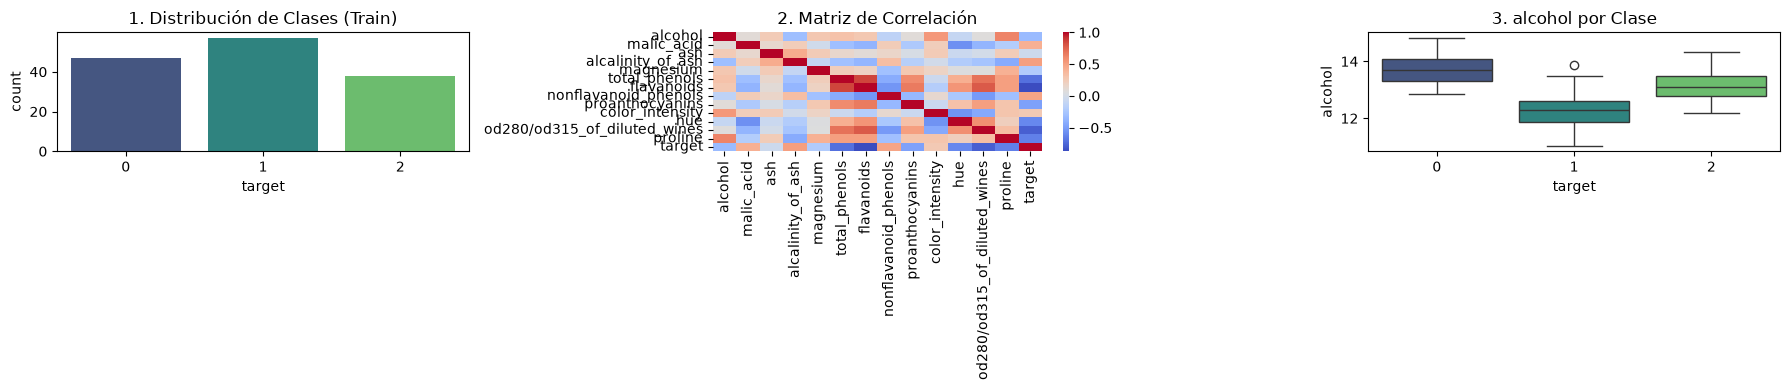

In [12]:
# TODO 4: Realiza el EDA sobre el conjunto de entrenamiento (train_df)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Distribución del Target
sns.countplot(data=train_df, x="target", ax=axes[0], palette="viridis")
axes[0].set_title("1. Distribución de Clases (Train)")

# 2. Correlación con el Target
corr = train_df.corr()
sns.heatmap(corr, cmap="coolwarm", annot=False, ax=axes[1])
axes[1].set_title("2. Matriz de Correlación")

# 3. Boxplot de una variable clave por clase
feature_col = [col for col in train_df.columns if col != "target"][0]
sns.boxplot(data=train_df, x="target", y=feature_col, ax=axes[2], palette="viridis")
axes[2].set_title(f"3. {feature_col} por Clase")

plt.tight_layout()
plt.show()

**Hallazgos:**

1. La estratificación garantizó que las clases de vino se mantengan bien representadas en el conjunto de entrenaminto y no se desbalancea muy exageradamente.
2. Existen pares de variables que se relacionan bastante entre si como por ejemplo flavanoides y fenoles, lo que sugiere que algunas características podrían necesitar un escalado o una selección de características en etapas posteriores.
3. Multiples variables continuas muestran rangos claramente diferenciados por cada tipo de vino, por lo que los clasificadores lineales tienen buen desempeño.

## 4. Persistencia de datos y contrato

In [13]:
# 1. Se reinician los índices y guarda CSVs sin el índice
train_df.reset_index(drop=True).to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.reset_index(drop=True).to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# 2. Se crea el contrato de datos
feature_names = [col for col in df.columns if col != "target"]

data_contract = {
    "target": "target",
    "features": feature_names,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "n_train_samples": len(train_df),
    "n_test_samples": len(test_df)
}

# 3. Aquí se guarda el json en artifacts
with open(ARTIFACTS_DIR / "data_contract.json", "w") as f:
    json.dump(data_contract, f, indent=4)

print("Archivos y contrato de datos guardados exitosamente.")

Archivos y contrato de datos guardados exitosamente.


In [14]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.